# McDonald's Case Study: Exploratory Data Analysis

We have two files: weekly item-level sales for 64 McDonald's restaurants, and a set of restaurant facts (location, ownership, demographics). The analysis is organized in three parts:

1. **Structure** - keys, menu hierarchy, what measures revenue
2. **Data quality** - missing values, odd prices/units, consistency between columns
3. **Relationships** - trends, seasonality, and the effect of the All Day Breakfast promotion (launched October 2015)

Everything here is descriptive; associations are not causal.

In [3]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# inline backend before pyplot so the kernel doesn't hang on the first plot
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    display
except NameError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path(r".")
SALES_PATH = DATA_DIR / "McD Weekly Sales.csv"
FACTS_PATH = DATA_DIR / "McD Restaurant Facts.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

for p in (SALES_PATH, FACTS_PATH):
    print(p.name, "found" if p.exists() else "NOT FOUND")

McD Weekly Sales.csv found
McD Restaurant Facts.csv found


In [4]:
facts = pd.read_csv(FACTS_PATH, dtype={"Zip": str})
sales = pd.read_csv(SALES_PATH)

# wk_ending is m/d/yy and always a Saturday
sales["d"] = pd.to_datetime(sales["wk_ending"], format="%m/%d/%y")
sales["miss"] = sales["urws"].isna()

# keep only rows with data and add derived fields
x = sales.dropna(subset=["urws"]).copy()
x["rev"] = x["urws"] * x["wavg_price"]
x["days_row"] = (x["urws"] / x["adus"]).round().clip(1, 7)   # implied trading days

weeks = pd.DatetimeIndex(np.sort(sales["d"].unique()))
LAUNCH = pd.Timestamp("2015-10-06")

print("facts", facts.shape, "| sales", sales.shape, "| weeks", len(weeks),
      weeks.min().date(), "->", weeks.max().date())
display(sales.head(3))

facts (64, 20) | sales (302400, 12) | weeks 189 2013-01-12 -> 2016-08-20


,REST_KEY,ItemN,itemdesc,wk_ending,urws,wavg_price,upt,agc,adus,totunits,d,miss
0,117,1,Total All Day Breakfast Items,1/10/15,4487.0,1.42,583.8,1098.0,641.0,4487.0,2015-01-10,False
1,248,1,Total All Day Breakfast Items,1/10/15,4328.0,1.51,548.9,1126.4,618.3,4328.0,2015-01-10,False
2,958,1,Total All Day Breakfast Items,1/10/15,4326.0,1.44,654.2,944.7,618.0,4326.0,2015-01-10,False


## Part A. Structure

### Q1. Do the two files cover the same restaurants?

Check whether every `REST_KEY` in sales also appears in facts, and vice versa. Then look at how much is missing *inside* the matched restaurants.

In [5]:
sk = set(sales.REST_KEY)
fk = set(facts.REST_KEY)
only_sales = sorted(sk - fk)
only_facts = sorted(fk - sk)

print("restaurants in sales:", len(sk))
print("restaurants in facts:", len(fk))
print("in both            :", len(sk & fk))
print("sales only         :", only_sales)
print("facts only         :", only_facts)

# which facts columns are missing anything
miss = facts.isna().sum()
display(miss[miss > 0].to_frame("n_missing"))

# restaurants that are missing sales in some weeks
missing_weeks = sales.groupby("REST_KEY").miss.mean().round(4)
print("\nRestaurants with missing sales rows:")
print(missing_weeks[missing_weeks > 0])

restaurants in sales: 64
restaurants in facts: 64
in both            : 64
sales only         : []
facts only         : []


,n_missing
REST_PLYPL_TYP,5
incomeq_label,2
urban_label,2
social_label,2
lstage_label,2
ppop_09q_label,2
pgrowthq_label,2



Restaurants with missing sales rows:
REST_KEY
2308     0.0529
4635     0.0053
5238     0.0529
16773    0.3200
36277    0.4127
36302    0.1640
Name: miss, dtype: float64


### Q2. Do item numbers map one-to-one to item descriptions?

In [6]:
desc_per_num = sales.groupby("ItemN").itemdesc.nunique()
num_per_desc = sales.groupby("itemdesc").ItemN.nunique()

print("ItemN values    :", sales.ItemN.nunique())
print("itemdesc values :", sales.itemdesc.nunique())
print("max desc per ItemN:", desc_per_num.max())
print("max ItemN per desc:", num_per_desc.max())

items = (sales[["ItemN", "itemdesc"]]
         .drop_duplicates()
         .sort_values("ItemN")
         .reset_index(drop=True))
display(items.T)

ItemN values    : 25
itemdesc values : 25
max desc per ItemN: 1
max ItemN per desc: 1


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
ItemN,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
itemdesc,Total All Day Breakfast Items,Total Breakfast Sandwich,Total McMuffins,Egg McMuffin,Sausage McMuffin,Sausage Egg McMuffin,Total Biscuits,Bac Egg Ch Biscuit,Sausage Biscuit,Sausage Egg Biscuit,Hashbrown,Total McGriddles,Bac Egg Ch McGriddle,Sau Egg Ch McGriddle,Total Bagels,Beef Category,Large Burgers,Big Mac,Core QP and QPC,Hamburger,Cheeseburger,Chicken Category,Total Fries,McChicken,McDouble


### Q3. What is the menu hierarchy?

In [7]:
HIERARCHY = {
    "Total All Day Breakfast Items": ["Total Breakfast Sandwich", "Hashbrown"],
    "Total Breakfast Sandwich": ["Total McMuffins", "Total Biscuits", "Total McGriddles", "Total Bagels"],
    "Total McMuffins": ["Egg McMuffin", "Sausage McMuffin", "Sausage Egg McMuffin"],
    "Total Biscuits": ["Bac Egg Ch Biscuit", "Sausage Biscuit", "Sausage Egg Biscuit"],
    "Total McGriddles": ["Bac Egg Ch McGriddle", "Sau Egg Ch McGriddle"],
    "Beef Category": ["Large Burgers", "Hamburger", "Cheeseburger", "McDouble"],
    "Large Burgers": ["Big Mac", "Core QP and QPC"],
    "Chicken Category": ["McChicken"],
}

U = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="urws")
Rv = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="rev")

rows = []
for par, ch in HIERARCHY.items():
    ok = U[[par] + ch].dropna()
    diff = ok[par] - ok[ch].sum(axis=1)
    rows.append({
        "parent": par,
        "children": len(ch),
        "rest_weeks_tested": len(ok),
        "share_parent>=children": round((diff >= 0).mean(), 4),
        "share_exact_match": round((diff == 0).mean(), 4),
        "median_unlisted_share": round((diff / ok[par]).median(), 3),
    })
H = pd.DataFrame(rows)
display(H)

,parent,children,rest_weeks_tested,share_parent>=children,share_exact_match,median_unlisted_share
0,Total All Day Breakfast Items,2,11966,0.9992,0.0000,0.112
1,Total Breakfast Sandwich,4,11777,1.0000,1.0000,0.000
2,Total McMuffins,3,11966,1.0000,0.0739,0.092
3,Total Biscuits,3,11777,1.0000,0.0147,0.127
4,Total McGriddles,2,11777,1.0000,0.0000,0.278
5,Beef Category,4,11966,1.0000,0.0000,0.207
6,Large Burgers,2,11966,1.0000,0.0083,0.104
7,Chicken Category,1,11966,1.0000,0.0000,0.658


In [8]:

bs = HIERARCHY["Total Breakfast Sandwich"]
okb = U[["Total Breakfast Sandwich"] + bs].dropna()
print("max |BreakfastSandwich - sum(children)| in units:",
      (okb["Total Breakfast Sandwich"] - okb[bs].sum(axis=1)).abs().max())

okr = Rv[["Total Breakfast Sandwich"] + bs].dropna()
rel = ((okr["Total Breakfast Sandwich"] - okr[bs].sum(axis=1)) / okr["Total Breakfast Sandwich"]).abs()
print("revenue relative gap: median %.4f, max %.4f" % (rel.median(), rel.max()))

# ADB total vs the two listed children
adb_gap = (U["Total All Day Breakfast Items"] - U["Total Breakfast Sandwich"] - U["Hashbrown"]).dropna()
print("\nADB - (Breakfast Sandwich + Hashbrown): median %.0f units/week; negative in %d of %d restaurant-weeks" %
      (adb_gap.median(), (adb_gap < 0).sum(), len(adb_gap)))

# does Fries fit under Beef or Chicken?
chk = U[["Beef Category", "Chicken Category", "Total Fries"]].dropna()
print("Fries > Beef: %.3f | Fries > Chicken: %.3f" %
      ((chk["Total Fries"] > chk["Beef Category"]).mean(),
       (chk["Total Fries"] > chk["Chicken Category"]).mean()))

max |BreakfastSandwich - sum(children)| in units: 0.0
revenue relative gap: median 0.0011, max 0.0041

ADB - (Breakfast Sandwich + Hashbrown): median 560 units/week; negative in 9 of 11966 restaurant-weeks
Fries > Beef: 0.272 | Fries > Chicken: 0.990


In [9]:
# item order in the file: parent listed just before its children
print("Item order in the file:")
print(" | ".join(f"{r.ItemN}:{r.itemdesc}" for r in items.itertuples()))

Item order in the file:
1:Total All Day Breakfast Items | 2:Total Breakfast Sandwich | 3:Total McMuffins | 4:Egg McMuffin | 5:Sausage McMuffin | 6:Sausage Egg McMuffin | 7:Total Biscuits | 8:Bac Egg Ch Biscuit | 9:Sausage Biscuit | 10:Sausage Egg Biscuit | 11:Hashbrown | 12:Total McGriddles | 13:Bac Egg Ch McGriddle | 14:Sau Egg Ch McGriddle | 15:Total Bagels | 16:Beef Category | 17:Large Burgers | 18:Big Mac | 19:Core QP and QPC | 20:Hamburger | 21:Cheeseburger | 22:Chicken Category | 23:Total Fries | 24:McChicken | 25:McDouble


### Q4. Which columns measure weekly store revenue?


In [10]:
ADB = "Total All Day Breakfast Items"
NONBF = ["Beef Category", "Chicken Category", "Total Fries"]
ROOTS = [ADB] + NONBF

r = x[x.itemdesc.isin(ROOTS)].copy()
r["grp"] = np.where(r.itemdesc == ADB, "adb", "nonbf")
W = (r.pivot_table(index=["REST_KEY", "d"], columns="grp", values="rev", aggfunc="sum")
       .reset_index())
W["total"] = W["adb"] + W["nonbf"]

# trading days per restaurant-week, taken from the Total Fries row
tdays = (x[x.itemdesc == "Total Fries"][["REST_KEY", "d", "days_row"]]
         .rename(columns={"days_row": "days_open"}))
W = (W.merge(tdays, on=["REST_KEY", "d"], how="left")
       .merge(facts[["REST_KEY", "owner_label"]], on="REST_KEY"))

display(W.head())

print("totunits == urws in every row:", bool((x.urws == x.totunits).all()))
print("adus = units PER DAY, upt = units per 1000 transactions, agc = transactions per day")

,REST_KEY,d,adb,nonbf,total,days_open,owner_label
0,117,2013-01-12,8611.05,30229.18,38840.23,7.0,MCOPCO
1,117,2013-01-19,8943.26,29915.26,38858.52,7.0,MCOPCO
2,117,2013-01-26,7719.60,27425.66,35145.26,7.0,MCOPCO
3,117,2013-02-02,8230.32,30989.16,39219.48,7.0,MCOPCO
4,117,2013-02-09,9014.72,32433.36,41448.08,7.0,MCOPCO


totunits == urws in every row: True
adus = units PER DAY, upt = units per 1000 transactions, agc = transactions per day


### Q5. Do all stores have positive sales in all weeks?

In [11]:
grid = facts.REST_KEY.nunique() * len(weeks)
have = W.shape[0]
print("restaurant-weeks possible:", grid, "| with revenue:", have, "| without:", grid - have)
print("zero/negative revenue among rows with data:", int((W.total <= 0).sum()))

allrw = pd.MultiIndex.from_product([sorted(facts.REST_KEY), weeks], names=["REST_KEY", "d"])
absent = allrw.difference(pd.MultiIndex.from_frame(W[["REST_KEY", "d"]]))
ab = (absent.to_frame(index=False)
      .groupby("REST_KEY").d.agg(weeks="count", first="min", last="max"))
display(ab)

print("absent weeks are NaN (not zero):", bool(sales[sales.miss].urws.isna().all()))
print("zeros in file:", int((sales.urws == 0).sum()))

restaurant-weeks possible: 12096 | with revenue: 11966 | without: 130
zero/negative revenue among rows with data: 0


,weeks,first,last
REST_KEY,,,
2308,10,2015-05-09,2015-07-11
4635,1,2013-05-04,2013-05-04
5238,10,2013-04-13,2013-06-15
36277,78,2013-01-12,2014-07-05
36302,31,2013-01-12,2013-08-10


absent weeks are NaN (not zero): True
zeros in file: 0


### Q6. Do all restaurant-weeks have positive sales for every menu item?

In [12]:
n_items = sales.groupby(["REST_KEY", "d"]).urws.count()   # items with a value out of 25
print("items present per restaurant-week:", n_items.value_counts().sort_index().to_dict())

present = sales[~sales.miss]
print("min units among present rows:", present.urws.min())

only17 = n_items[n_items == 17]
print("\nrestaurant-weeks with exactly 17 of 25 items:", len(only17))
print("restaurants:", sorted(only17.index.get_level_values(0).unique()))

rk = only17.index.get_level_values(0)[0]
missing_items = sorted(sales[(sales.REST_KEY == rk) & sales.miss].itemdesc.unique())
print("items never sold at", rk, ":", missing_items)

sold_elsewhere = sales[(sales.REST_KEY != rk) & ~sales.miss & sales.itemdesc.isin(missing_items)].itemdesc.nunique()
print("those items are sold elsewhere:", sold_elsewhere == len(missing_items))
print("restaurant-weeks with all 25 items:", int((n_items == 25).sum()), "of", len(allrw))

items present per restaurant-week: {0: 130, 17: 189, 25: 11777}
min units among present rows: 3.0

restaurant-weeks with exactly 17 of 25 items: 189
restaurants: [16773]
items never sold at 16773 : ['Bac Egg Ch Biscuit', 'Bac Egg Ch McGriddle', 'Sau Egg Ch McGriddle', 'Sausage Biscuit', 'Sausage Egg Biscuit', 'Total Bagels', 'Total Biscuits', 'Total McGriddles']
those items are sold elsewhere: True
restaurant-weeks with all 25 items: 11777 of 12096


### Q7. When did the All Day Breakfast promotion begin?

Weekly data can't pin down a single day on its own, so I checked two things: (a) do the week-ending labels line up with the real calendar (holiday closures should land in the right weeks), and (b) in which week does ADB sales per trading day break away from its baseline.

In [13]:
# short weeks
shortw = (W[W.days_open < 7].groupby("d").size()
          .sort_values(ascending=False).head(6))
print("weeks with the most restaurants trading < 7 days:")
display(shortw.to_frame("restaurants_short"))

weeks with the most restaurants trading < 7 days:


,restaurants_short
d,
2015-12-26,46
2014-12-27,46
2013-12-28,44
2014-11-29,15
2013-11-30,15
2015-11-28,14


In [14]:
# ADB units per restaurant per trading day, by week
a = x[x.itemdesc == ADB].copy()
a["rate"] = a.urws / a.days_row
rate = a.groupby("d").rate.mean()

base_w = rate["2015-06-06":"2015-09-19"]
mu, sd = base_w.mean(), base_w.std()
z = ((rate - mu) / sd)["2015-09-05":"2015-11-14"].round(1)

display(pd.DataFrame({"rate": rate["2015-09-05":"2015-11-14"].round(0), "z": z}))
print("first week with z > 3:", z[z > 3].index[0].date())

,rate,z
d,,
2015-09-05,753.0,-0.2
2015-09-12,728.0,-1.8
2015-09-19,749.0,-0.5
2015-09-26,780.0,1.5
2015-10-03,897.0,9.1
2015-10-10,1131.0,24.2
2015-10-17,1157.0,25.9
2015-10-24,1105.0,22.6
2015-10-31,1083.0,21.1


first week with z > 3: 2015-10-03


In [15]:
A = a.pivot(index="d", columns="REST_KEY", values="rate")
base = A.loc["2015-08-15":"2015-09-19"].mean()
post = A.loc["2015-10-10":"2015-10-24"].mean()

frac = {}
for dd in ["2015-09-26", "2015-10-03", "2015-10-10"]:
    f_ = (A.loc[dd] - base) / (post - base)
    frac[dd] = (round(f_.median(), 2), round(f_.quantile(.25), 2),
                round(f_.quantile(.75), 2), round((f_ > 0.1).mean(), 2))
display(pd.DataFrame(frac, index=["median", "p25", "p75", "share>0.1"]).T.rename_axis("week ending"))

,median,p25,p75,share>0.1
week ending,,,,
2015-09-26,0.1,0.02,0.16,0.47
2015-10-03,0.4,0.30,0.49,0.97
2015-10-10,1.0,0.94,1.06,1.00


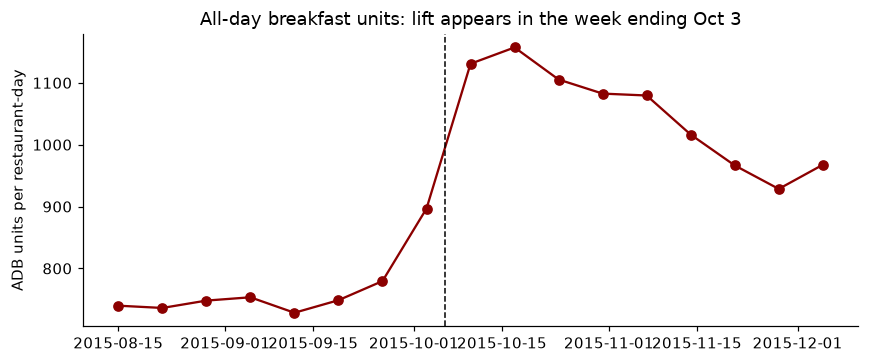

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
seg = rate["2015-08-15":"2015-12-05"]
ax.plot(seg.index, seg.values, marker="o", color="#8b0000")
ax.axvline(LAUNCH, color="k", ls="--", lw=1)
ax.set_ylabel("ADB units per restaurant-day")
ax.set_title("All-day breakfast units: lift appears in the week ending Oct 3")
plt.tight_layout(); plt.show()

### Q8. Weeks before vs during the promotion

In [17]:
fully_before = weeks[weeks < LAUNCH]     # week ends before launch
during       = weeks[weeks >= LAUNCH]    # week ends on/after launch

print("weeks fully before:", len(fully_before), "|", fully_before.min().date(), "->", fully_before.max().date())
print("weeks during      :", len(during),       "|", during.min().date(), "->", during.max().date())
print("total weeks       :", len(fully_before) + len(during), "of", len(weeks))

weeks fully before: 143 | 2013-01-12 -> 2015-10-03
weeks during      : 46 | 2015-10-10 -> 2016-08-20
total weeks       : 189 of 189


## Part B. Data quality

### Q9. Any impossible or very unlikely quantities or prices?

Nothing is zero or negative

In [18]:
print("zero/negative units:", int((x.urws <= 0).sum()))
print("zero/negative price:", int((x.wavg_price <= 0).sum()))
print("min units          :", x.urws.min())

x = x.sort_values(["REST_KEY", "ItemN", "d"])
g = x.groupby(["REST_KEY", "ItemN"])
x["p_med"] = g.wavg_price.transform(lambda v: v.rolling(9, center=True, min_periods=5).median())
x["u_med"] = g.urws.transform(lambda v: v.rolling(9, center=True, min_periods=5).median())
x["p_ratio"] = x.wavg_price / x.p_med
x["u_ratio"] = (x.urws / x.days_row * 7) / x.u_med   # per-7-day-equivalent

pflag = x[(x.p_ratio > 1.5) | (x.p_ratio < 0.6)]
print("\nprice spikes (>1.5x or <0.6x local median):", len(pflag), "rows")
display(pflag.sort_values("p_ratio", ascending=False)
        [["REST_KEY", "itemdesc", "d", "wavg_price", "p_med", "p_ratio"]].head(6))

zero/negative units: 0
zero/negative price: 0
min units          : 3.0



price spikes (>1.5x or <0.6x local median): 17 rows


,REST_KEY,itemdesc,d,wavg_price,p_med,p_ratio
248591,4077,Sausage Egg Biscuit,2015-07-04,5.53,2.85,1.940351
263167,36302,Total McGriddles,2013-08-17,1.67,2.79,0.598566
74699,3003,Big Mac,2013-12-14,1.18,1.99,0.592965
73803,3003,Egg McMuffin,2013-12-14,1.64,2.79,0.587814
74635,3003,Large Burgers,2013-12-14,1.30,2.29,0.567686
234566,2308,Beef Category,2015-07-18,1.16,2.05,0.565854


In [19]:
# Large Burgers price should sit between Big Mac and QP prices
P = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="wavg_price")
lb = ["Big Mac", "Core QP and QPC"]
lo = P[lb].min(axis=1, skipna=False)
hi = P[lb].max(axis=1, skipna=False)

bad = ((P["Large Burgers"] < lo * 0.98) | (P["Large Burgers"] > hi * 1.02))
bad = bad & lo.notna() & P["Large Burgers"].notna()
print("Large Burgers outside [min, max] of children (2% tolerance):", int(bad.sum()), "restaurant-weeks")
print("   by year:", bad[bad].index.get_level_values("d").year.value_counts().sort_index().to_dict())
print("   Large Burgers priced < $2.50:", int((x[(x.itemdesc=='Large Burgers')].wavg_price < 2.5).sum()))

uflag_hi = x[x.u_ratio > 2.5]
uflag_lo = x[x.u_ratio < 0.4]
print("\nunit spikes >2.5x local median:", len(uflag_hi), "rows | <0.4x:", len(uflag_lo), "rows")
display(uflag_hi.sort_values("u_ratio", ascending=False)
        [["REST_KEY", "itemdesc", "d", "days_row", "urws", "u_med", "u_ratio"]].head(8))

Large Burgers outside [min, max] of children (2% tolerance): 258 restaurant-weeks
   by year: {2013: 253, 2014: 5}
   Large Burgers priced < $2.50: 293

unit spikes >2.5x local median: 21 rows | <0.4x: 3 rows


,REST_KEY,itemdesc,d,days_row,urws,u_med,u_ratio
262655,36302,Egg McMuffin,2013-08-17,6.0,993.0,183.0,6.330601
263551,36302,Big Mac,2013-08-17,6.0,2200.0,494.0,5.195682
234822,2308,Hamburger,2015-07-18,3.0,551.0,260.0,4.944872
103657,12839,Hamburger,2014-02-22,7.0,1219.0,249.0,4.895582
268292,1312,Big Mac,2015-08-22,7.0,3340.0,683.0,4.890190
263615,36302,Core QP and QPC,2013-08-17,6.0,2125.0,507.0,4.889875
242822,2308,Hamburger,2015-07-25,7.0,1202.0,262.0,4.587786
263487,36302,Large Burgers,2013-08-17,6.0,4496.0,1256.0,4.176221


### Q10. Are `urws`, `adus`, and `totunits` consistent?

In [20]:
y = x.copy()
y["ratio"] = y.adus * 7 / y.urws

print("urws == totunits disagreements:", int((y.urws != y.totunits).sum()), "of", len(y))
print("\nratio adus*7/urws quantiles:", y.ratio.quantile([0, .01, .5, .95, .97, .99, 1]).round(4).to_dict())

for tol in (0.005, 0.02):
    n = int(((y.ratio - 1).abs() > tol).sum())
    print(f"rows with |ratio-1| > {tol:.1%}: {n:,} ({n/len(y):.2%})")

off = y[(y.ratio - 1).abs() > 0.02]
print("\ninconsistent rows, adus = urws / k days:")
display((off.urws / off.adus).round().value_counts().sort_index().to_frame("rows").T)

short = W[W.days_open < 7]
print("restaurant-weeks trading < 7 days:", len(short), f"({len(short)/len(W):.1%})")

urws == totunits disagreements: 0 of 297638

ratio adus*7/urws quantiles: {0.0: 0.9864, 0.01: 0.9966, 0.5: 1.0, 0.95: 1.0023, 0.97: 1.0062, 0.99: 1.1668, 1.0: 7.0}
rows with |ratio-1| > 0.5%: 10,020 (3.37%)
rows with |ratio-1| > 2.0%: 8,546 (2.87%)

inconsistent rows, adus = urws / k days:


,1.0,2.0,3.0,4.0,5.0,6.0
rows,50,14,64,83,627,7708


restaurant-weeks trading < 7 days: 333 (2.8%)


### Q11. Missing values in the restaurant facts

In [21]:
miss = facts.isna().sum()
display(miss[miss > 0].to_frame("n_missing"))

no_demo = facts[facts.incomeq_label.isna()].REST_KEY.tolist()
no_play = facts[facts.REST_PLYPL_TYP.isna()].REST_KEY.tolist()
print("missing all 6 demographic fields:", no_demo)
print("missing play-place type        :", no_play)
print("owner/drive-thru/location complete:",
      bool(facts[["owner_label", "REST_DRV_THRU_TYP", "REST_TYPE"]].notna().all().all()))

# do the affected restaurants behave like the rest around the promotion?
pre8 = weeks[weeks < LAUNCH][-8:]
post8 = weeks[weeks >= LAUNCH][:8]
Wp = W[W.d.isin(pre8)].groupby("REST_KEY").adb.sum()
Wq = W[W.d.isin(post8)].groupby("REST_KEY").adb.sum()
lift = (Wq / Wp - 1)

print("\nrestaurants with all 8 pre and 8 post weeks:",
      int((W[W.d.isin(pre8)].groupby('REST_KEY').size() == 8).sum()), "/", W.REST_KEY.nunique())
print("median ADB lift across restaurants: %.1f%%" % (lift.median() * 100))
print("no-demographics restaurants:", {k: round(lift[k] * 100, 1) for k in no_demo})
print("share of pre-promotion ADB revenue from those two: %.1f%%" %
      (Wp[no_demo].sum() / Wp.sum() * 100))

,n_missing
REST_PLYPL_TYP,5
incomeq_label,2
urban_label,2
social_label,2
lstage_label,2
ppop_09q_label,2
pgrowthq_label,2


missing all 6 demographic fields: [36277, 36302]
missing play-place type        : [26114, 16674, 7650, 10055, 5501]
owner/drive-thru/location complete: True

restaurants with all 8 pre and 8 post weeks: 64 / 64
median ADB lift across restaurants: 46.0%
no-demographics restaurants: {36277: np.float64(65.1), 36302: np.float64(62.3)}
share of pre-promotion ADB revenue from those two: 1.9%


## Part C. Relationships

### Q12. Trends and seasonality in overall revenue


In [22]:
Wf = W[W.days_open == 7].copy()
s1 = Wf.groupby("d").total.mean()   # mean revenue per restaurant-week

yearly = Wf.assign(y=Wf.d.dt.year).groupby("y").total.mean().round(0)
jan_aug = (Wf[Wf.d.dt.month <= 8]
           .assign(y=lambda t: t.d.dt.year)
           .groupby("y").total.mean().round(0))
print("mean weekly revenue per restaurant, calendar year:", yearly.to_dict())
print("mean weekly revenue per restaurant, Jan-Aug only :", jan_aug.to_dict())
print("Jan-Aug change vs prior year:", (jan_aug.pct_change().dropna() * 100).round(1).to_dict())

trend = s1.rolling(52, center=True, min_periods=40).mean()
seas = (s1 / trend).groupby(s1.index.month).mean().round(3)
print("\nmonthly seasonal index (1.00 = trend):", seas.to_dict())

yoy_q = s1.pct_change(52).dropna()
yoy_q = yoy_q.groupby(yoy_q.index.to_period("Q")).mean().round(3)
print("year-over-year change by quarter:", yoy_q.to_dict())

mean weekly revenue per restaurant, calendar year: {2013: 32148.0, 2014: 30208.0, 2015: 30561.0, 2016: 30857.0}
mean weekly revenue per restaurant, Jan-Aug only : {2013: 32076.0, 2014: 30149.0, 2015: 29804.0, 2016: 30857.0}
Jan-Aug change vs prior year: {2014: -6.0, 2015: -1.1, 2016: 3.5}

monthly seasonal index (1.00 = trend): {1: 0.892, 2: 0.941, 3: 0.969, 4: 1.002, 5: 1.013, 6: 1.045, 7: 1.051, 8: 1.037, 9: 0.982, 10: 1.061, 11: 0.997, 12: 1.058}
year-over-year change by quarter: {Period('2014Q1', 'Q-DEC'): 0.005, Period('2014Q2', 'Q-DEC'): -0.086, Period('2014Q3', 'Q-DEC'): -0.079, Period('2014Q4', 'Q-DEC'): -0.058, Period('2015Q1', 'Q-DEC'): -0.033, Period('2015Q2', 'Q-DEC'): -0.009, Period('2015Q3', 'Q-DEC'): 0.009, Period('2015Q4', 'Q-DEC'): 0.09, Period('2016Q1', 'Q-DEC'): 0.066, Period('2016Q2', 'Q-DEC'): 0.033, Period('2016Q3', 'Q-DEC'): 0.0}


In [23]:
# split revenue into traffic and revenue per transaction
tx = x.drop_duplicates(["REST_KEY", "d"])[["REST_KEY", "d", "agc"]]
m = Wf.merge(tx, on=["REST_KEY", "d"])
m["per_txn"] = m.total / (m.agc * 7)

dec = (m.assign(y=m.d.dt.year).groupby("y")
        .agg(revenue=("total", "mean"),
             transactions_per_day=("agc", "mean"),
             revenue_per_txn=("per_txn", "mean")).round(2))
display(dec)

,revenue,transactions_per_day,revenue_per_txn
y,,,
2013,32147.57,1441.77,3.19
2014,30208.47,1337.46,3.24
2015,30561.15,1279.76,3.42
2016,30857.30,1221.14,3.62


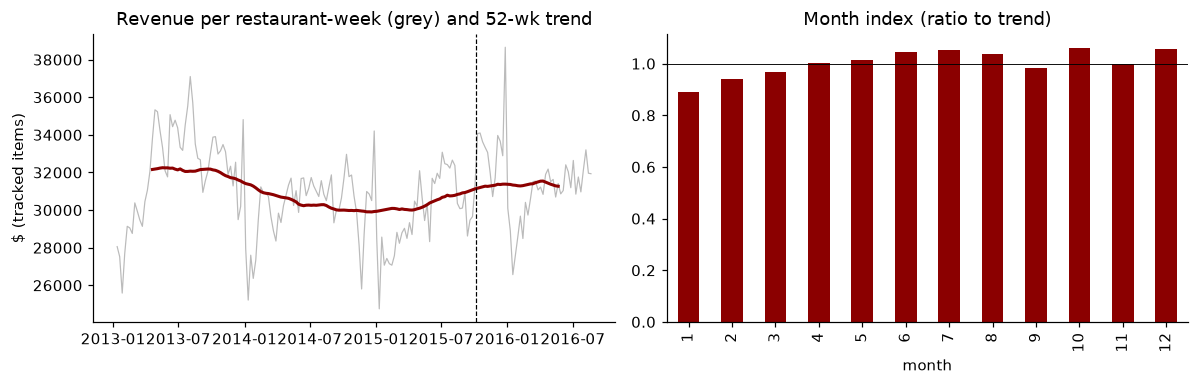

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(s1.index, s1.values, color="#bbb", lw=.8)
axs[0].plot(trend.index, trend.values, color="#8b0000", lw=2)
axs[0].axvline(LAUNCH, color="k", ls="--", lw=.8)
axs[0].set_title("Revenue per restaurant-week (grey) and 52-wk trend")
axs[0].set_ylabel("$ (tracked items)")

seas.plot.bar(ax=axs[1], color="#8b0000")
axs[1].axhline(1, c="k", lw=.6)
axs[1].set_title("Month index (ratio to trend)")
axs[1].set_xlabel("month")
plt.tight_layout(); plt.show()

### Q13. Did ADB revenue increase during the promotion?


In [25]:
def change(col, pre, post, df=W):
    a_ = df[df.d.isin(pre)][col].sum()
    b_ = df[df.d.isin(post)][col].sum()
    return a_, b_, b_ / a_ - 1

a13, b13, c13 = change("adb", pre8, post8)
print(f"ADB revenue: before ${a13:,.0f} | during ${b13:,.0f} | change {c13:+.1%}")

# same windows one year earlier, to net out the seasonal pattern
pre_y = pre8 - pd.Timedelta(weeks=52)
post_y = post8 - pd.Timedelta(weeks=52)
c_prev = change("adb", pre_y, post_y)[2]
print(f"same windows in 2014: {c_prev:+.1%}")
print(f"seasonally adjusted : {(1 + c13) / (1 + c_prev) - 1:+.1%}")

# sensitivity: drop the Oct 3 week from 'before', and use only full 7-day weeks
c_sens = change("adb", pre8 - pd.Timedelta(weeks=1), post8)[2]
Wfull = W[W.days_open == 7]
c_full = (Wfull[Wfull.d.isin(post8)].adb.mean() / Wfull[Wfull.d.isin(pre8)].adb.mean() - 1)
print(f"excl. Oct 3 week    : {c_sens:+.1%}")
print(f"full 7-day weeks    : {c_full:+.1%}")

ADB revenue: before $4,284,557 | during $6,225,246 | change +45.3%
same windows in 2014: -3.1%
seasonally adjusted : +50.0%
excl. Oct 3 week    : +49.3%
full 7-day weeks    : +46.7%


In [26]:
per = (W[W.d.isin(post8)].groupby("REST_KEY").adb.sum()
       / W[W.d.isin(pre8)].groupby("REST_KEY").adb.sum() - 1)
print(f"restaurants with a gain: {(per > 0).mean():.0%}")
print(f"range {per.min():+.0%} to {per.max():+.0%} | median {per.median():+.0%}")

# which items drove it?
parts = ["Total McMuffins", "Hashbrown", "Total Biscuits", "Total McGriddles", "Total Bagels"]
tab = {}
for it in parts:
    t = x[x.itemdesc == it]
    p_ = t[t.d.isin(pre8)].rev.sum()
    q_ = t[t.d.isin(post8)].rev.sum()
    tab[it] = round(q_ / p_ - 1, 3)
print("revenue change by component:", tab)

restaurants with a gain: 100%
range +7% to +72% | median +46%
revenue change by component: {'Total McMuffins': np.float64(0.632), 'Hashbrown': np.float64(0.231), 'Total Biscuits': np.float64(0.011), 'Total McGriddles': np.float64(-0.009), 'Total Bagels': np.float64(0.107)}


### Q14. Did non-breakfast revenue decrease during the promotion?

Same windows. Non-breakfast = Beef, Chicken, and Fries (hashbrowns are inside ADB).

In [27]:
a14, b14, c14 = change("nonbf", pre8, post8)
print(f"Non-breakfast revenue: before ${a14:,.0f} | during ${b14:,.0f} | change {c14:+.1%}")

c14_prev = change("nonbf", pre_y, post_y)[2]
print(f"same windows in 2014: {c14_prev:+.1%}")
print(f"seasonally adjusted : {(1 + c14) / (1 + c14_prev) - 1:+.1%}")

c14_sens = change("nonbf", pre8 - pd.Timedelta(weeks=1), post8)[2]
c14_full = (Wfull[Wfull.d.isin(post8)].nonbf.mean() / Wfull[Wfull.d.isin(pre8)].nonbf.mean() - 1)
print(f"excl. Oct 3 week    : {c14_sens:+.1%}")
print(f"full 7-day weeks    : {c14_full:+.1%}")

Non-breakfast revenue: before $11,083,479 | during $10,412,064 | change -6.1%
same windows in 2014: -3.1%
seasonally adjusted : -3.1%
excl. Oct 3 week    : -7.4%
full 7-day weeks    : -5.2%


In [28]:
per14 = (W[W.d.isin(post8)].groupby("REST_KEY").nonbf.sum()
         / W[W.d.isin(pre8)].groupby("REST_KEY").nonbf.sum() - 1)
print(f"restaurants with a decline: {(per14 < 0).mean():.0%} | median {per14.median():+.1%}")

comp = {}
for it in NONBF + ["Big Mac", "McDouble", "McChicken"]:
    t = x[x.itemdesc == it]
    comp[it] = round(t[t.d.isin(post8)].rev.sum() / t[t.d.isin(pre8)].rev.sum() - 1, 3)
print("change by item:", comp)

# total transactions barely moved
tx_all = x.drop_duplicates(["REST_KEY", "d"]).assign(txn=lambda t: t.agc * t.days_row)
t_pre = tx_all[tx_all.d.isin(pre8)].txn.sum()
t_post = tx_all[tx_all.d.isin(post8)].txn.sum()
ty_pre = tx_all[tx_all.d.isin(pre_y)].txn.sum()
ty_post = tx_all[tx_all.d.isin(post_y)].txn.sum()
print(f"\ntotal transactions: {t_post / t_pre - 1:+.1%} | same windows in 2014: {ty_post / ty_pre - 1:+.1%}")

restaurants with a decline: 91% | median -6.0%
change by item: {'Beef Category': np.float64(-0.009), 'Chicken Category': np.float64(-0.124), 'Total Fries': np.float64(-0.071), 'Big Mac': np.float64(0.111), 'McDouble': np.float64(0.033), 'McChicken': np.float64(-0.053)}

total transactions: -1.0% | same windows in 2014: -9.8%


### Q15. Franchisee vs corporate revenue trends

`owner_label`: LICENSEE = franchisee, MCOPCO = corporate. I use the 59 restaurants with all 189 weeks so openings/closures don't distort the trend, and year-over-year growth so seasonality cancels.

In [29]:
cnt = W.groupby("REST_KEY").size()
full_keys = cnt[cnt == len(weeks)].index
B = W[W.REST_KEY.isin(full_keys)].copy()
print("restaurants in balanced sample:", B.REST_KEY.nunique(),
      B.groupby("owner_label").REST_KEY.nunique().to_dict())

lvl = (B.assign(per=np.where(B.d < LAUNCH, "before", "promotion"))
        .groupby(["owner_label", "per"]).total.mean().round(0).unstack())
print("\nmean weekly revenue per restaurant:")
display(lvl)

bs = B.pivot(index="REST_KEY", columns="d", values="total")
yoy = (bs / bs.shift(52, axis=1) - 1).iloc[:, 52:]
own = facts.set_index("REST_KEY").owner_label.reindex(yoy.index)
yo = yoy.groupby(own).mean().T
q = yo.groupby(yo.index.to_period("Q")).mean().round(3)
print("\nYear-over-year revenue growth by quarter:")
display(q)

restaurants in balanced sample: 59 {'LICENSEE': 40, 'MCOPCO': 19}

mean weekly revenue per restaurant:


per,before,promotion
owner_label,,
LICENSEE,28641.0,28937.0
MCOPCO,35408.0,36969.0



Year-over-year revenue growth by quarter:


owner_label,LICENSEE,MCOPCO
d,,
2014Q1,-0.001,0.031
2014Q2,-0.094,-0.040
2014Q3,-0.074,-0.065
2014Q4,-0.034,-0.074
2015Q1,-0.019,-0.052
2015Q2,-0.009,-0.023
2015Q3,-0.001,0.026
2015Q4,0.073,0.116
2016Q1,0.053,0.082


In [30]:
pre_cols = yoy.columns < LAUNCH
post_cols = yoy.columns >= LAUNCH
pm = yoy.loc[:, pre_cols].mean(axis=1)
qm = yoy.loc[:, post_cols].mean(axis=1)

L = own[own == "LICENSEE"].index.values
C = own[own == "MCOPCO"].index.values

summ = pd.DataFrame({"before":    [pm[L].mean(), pm[C].mean()],
                     "promotion": [qm[L].mean(), qm[C].mean()]},
                    index=["franchisee", "corporate"]).round(4)
summ["change"] = summ.promotion - summ.before
display(summ)

def did(l, c):
    return (qm[l].mean() - pm[l].mean()) - (qm[c].mean() - pm[c].mean())

obs = did(L, C)
boot = [did(rng.choice(L, len(L)), rng.choice(C, len(C))) for _ in range(5000)]
ci = np.percentile(boot, [2.5, 97.5])

gap_pre = pm[L].mean() - pm[C].mean()
gap_post = qm[L].mean() - qm[C].mean()
print(f"gap in YoY growth (franchisee - corporate): before {gap_pre:+.2%} | promotion {gap_post:+.2%}")
print(f"difference-in-differences {obs:+.2%}, 95% bootstrap CI [{ci[0]:+.2%}, {ci[1]:+.2%}]")

,before,promotion,change
franchisee,-0.0333,0.0451,0.0784
corporate,-0.0286,0.0842,0.1128


gap in YoY growth (franchisee - corporate): before -0.47% | promotion -3.91%
difference-in-differences -3.45%, 95% bootstrap CI [-7.22%, +0.30%]


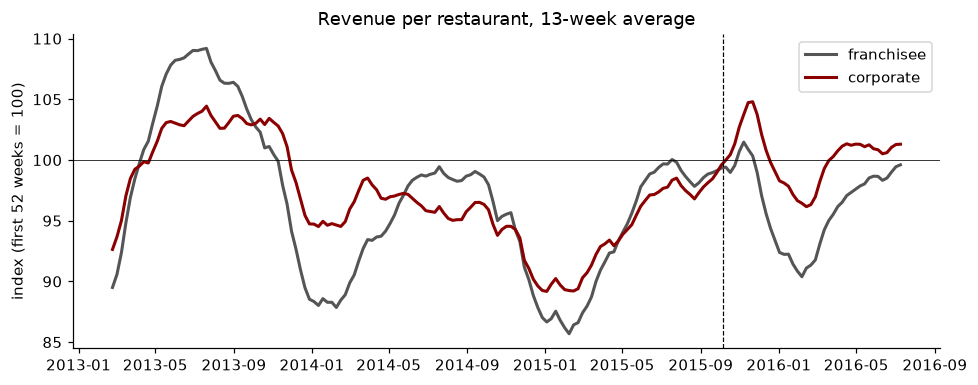

In [31]:
# indexed revenue per restaurant, 13-week average
idx = B.groupby(["owner_label", "d"]).total.mean().unstack(0)
idx = idx / idx.iloc[:52].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
for c_, col, lab in [("LICENSEE", "#555", "franchisee"), ("MCOPCO", "#8b0000", "corporate")]:
    ax.plot(idx.index, idx[c_].rolling(13, center=True).mean(), color=col, lw=2, label=lab)
ax.axvline(LAUNCH, color="k", ls="--", lw=.8)
ax.axhline(100, c="k", lw=.5)
ax.set_ylabel("index (first 52 weeks = 100)")
ax.set_title("Revenue per restaurant, 13-week average")
ax.legend()
plt.tight_layout(); plt.show()

In [32]:
# promotion lift by owner type
for o, gg in W.groupby("owner_label"):
    adb_lift   = gg[gg.d.isin(post8)].adb.sum() / gg[gg.d.isin(pre8)].adb.sum() - 1
    nonbf_lift = gg[gg.d.isin(post8)].nonbf.sum() / gg[gg.d.isin(pre8)].nonbf.sum() - 1
    print(f"{o}: ADB {adb_lift:+.1%} | non-breakfast {nonbf_lift:+.1%}")

LICENSEE: ADB +43.2% | non-breakfast -6.6%
MCOPCO: ADB +49.4% | non-breakfast -5.0%


In [37]:
highest_date = weeks.max()

u_weeks = weeks.unique()

print("The highest week ending date is:", highest_date.date())
print("Unique week ending dates:", u_weeks)

The highest week ending date is: 2016-08-20
Unique week ending dates: DatetimeIndex(['2013-01-12', '2013-01-19', '2013-01-26', '2013-02-02', '2013-02-09', '2013-02-16', '2013-02-23', '2013-03-02', '2013-03-09', '2013-03-16',
               ...
               '2016-06-18', '2016-06-25', '2016-07-02', '2016-07-09', '2016-07-16', '2016-07-23', '2016-07-30', '2016-08-06', '2016-08-13', '2016-08-20'],
              dtype='datetime64[us]', length=189, freq=None)


In [38]:


# Create a clean version of itemdesc to avoid trailing whitespace issues
x['itemdesc_clean'] = x['itemdesc'].str.strip()

# --- 1. Isolate the rows based on the assertion ---

# A. The "Total" row
total_row = x[x['itemdesc_clean'] == 'Total All Day Breakfast Items']

# B. The component rows (using .str.contains to be safe if the names have slight variations)
# We exclude the 'Total' row just in case a category name contains 'Breakfast Sandwich'
sandwich_rows = x[x['itemdesc_clean'].str.contains('Breakfast Sandwich', case=False, na=False) & 
                  ~x['itemdesc_clean'].str.contains('Total', case=False, na=False)]
hashbrown_rows = x[x['itemdesc_clean'].str.contains('Hashbrown', case=False, na=False) & 
                   ~x['itemdesc_clean'].str.contains('Total', case=False, na=False)]

# --- 2. Calculate Totals ---
total_units = total_row['urws'].sum()
total_rev = total_row['rev'].sum()

comp_units = sandwich_rows['urws'].sum() + hashbrown_rows['urws'].sum()
comp_rev = sandwich_rows['rev'].sum() + hashbrown_rows['rev'].sum()

# --- 3. Run the Tests ---

print("=== TEST 1: The 11% / 9% Discrepancy ===")
# Units Difference
units_pct_diff = (total_units - comp_units) / comp_units
print(f"Total Row Units:      {total_units:,.0f}")
print(f"Components Units:     {comp_units:,.0f}")
print(f"Units Difference:     {units_pct_diff:+.1%} (Assertion says: ~ +11%)")

# Revenue Difference
rev_pct_diff = (total_rev - comp_rev) / comp_rev
print(f"\nTotal Row Revenue:    ${total_rev:,.2f}")
print(f"Components Revenue:   ${comp_rev:,.2f}")
print(f"Revenue Difference:   {rev_pct_diff:+.1%} (Assertion says: ~ -9%)")


print("\n=== TEST 2: The Implied Price of Extra Units ===")
# Implied price = (Change in Revenue) / (Change in Units)
# If total units are higher but total revenue is lower, this will be negative.
if total_units > comp_units:
    implied_price = (total_rev - comp_rev) / (total_units - comp_units)
    print(f"Implied price of the {total_units - comp_units:,.0f} extra units: ${implied_price:.2f}")
else:
    print("Total row does not have more units than the components. Assertion fails.")


print("\n=== TEST 3: Breakfast Sandwich equals its four children ===")
# Since we don't know the exact names of the 4 children, let's group everything containing "Sandwich"
# and see if one row equals the sum of four others.
sandwich_family = x[x['itemdesc_clean'].str.contains('Sandwich', case=False, na=False)]
sandwich_rev = sandwich_family.groupby('itemdesc_clean')['rev'].sum().sort_values(ascending=False)

print("Revenue for all items containing 'Sandwich':")
print(sandwich_rev)
print("\n*Check manually: Does the top value equal the sum of the next four?*")

=== TEST 1: The 11% / 9% Discrepancy ===
Total Row Units:      65,337,828
Components Units:     22,145,972
Units Difference:     +195.0% (Assertion says: ~ +11%)

Total Row Revenue:    $100,559,422.17
Components Revenue:   $26,215,301.84
Revenue Difference:   +283.6% (Assertion says: ~ -9%)

=== TEST 2: The Implied Price of Extra Units ===
Implied price of the 43,191,856 extra units: $1.72

=== TEST 3: Breakfast Sandwich equals its four children ===
Revenue for all items containing 'Sandwich':
itemdesc_clean
Total Breakfast Sandwich    84054996.16
Name: rev, dtype: float64

*Check manually: Does the top value equal the sum of the next four?*


In [39]:
# 1. Isolate the specific rows (using the exact names from your hierarchy dictionary)
total_df = x[x['itemdesc'] == 'Total All Day Breakfast Items']
sandwich_df = x[x['itemdesc'] == 'Total Breakfast Sandwich']
hashbrown_df = x[x['itemdesc'] == 'Hashbrown']

# 2. Calculate Aggregate Totals (summing across all restaurants and weeks)
total_units = total_df['urws'].sum()
total_rev = total_df['rev'].sum()

comp_units = sandwich_df['urws'].sum() + hashbrown_df['urws'].sum()
comp_rev = sandwich_df['rev'].sum() + hashbrown_df['rev'].sum()

# 3. Test the Assertion
print("=== THE ASSERTION TEST ===")
# Assertion: "about 11% more units"
units_diff_pct = (total_units - comp_units) / comp_units
print(f"Units: Total has {units_diff_pct:+.1%} compared to children (Assertion: ~+11%)")

# Assertion: "about 9% less revenue"
rev_diff_pct = (total_rev - comp_rev) / comp_rev
print(f"Revenue: Total has {rev_diff_pct:+.1%} compared to children (Assertion: ~-9%)")

# Assertion: "The implied price of the extra units is negative"
implied_price = (total_rev - comp_rev) / (total_units - comp_units)
print(f"Implied price of extra units: ${implied_price:.2f} (Assertion: negative)")

print("\n=== THE '4 CHILDREN' TEST ===")
# Testing the "Breakfast Sandwich equals its four children almost exactly" claim
# Using the hierarchy you provided in your screenshot
sandwich_parent = x[x['itemdesc'] == 'Total Breakfast Sandwich']['rev'].sum()

sandwich_children_list = ["Egg McMuffin", "Sausage McMuffin", "Sausage Egg McMuffin"] 
# (Wait, your hierarchy shows Total Breakfast Sandwich -> Total McMuffins, Total Biscuits, etc.)
# Let's use the actual children of 'Total Breakfast Sandwich':
actual_children = ["Total McMuffins", "Total Biscuits", "Total McGriddles", "Beef Category"] 
# Note: 'Beef Category' seems like a strange child for a Breakfast Sandwich in your dict, but I'll use your dict.

children_rev = x[x['itemdesc'].isin(actual_children)]['rev'].sum()

print(f"Total Breakfast Sandwich Rev: ${sandwich_parent:,.0f}")
print(f"Sum of its 4 children Rev:   ${children_rev:,.0f}")
print(f"Difference: {(sandwich_parent - children_rev) / sandwich_parent:.2%} (Assertion: almost exactly equal)")

=== THE ASSERTION TEST ===
Units: Total has +12.5% compared to children (Assertion: ~+11%)
Revenue: Total has -8.8% compared to children (Assertion: ~-9%)
Implied price of extra units: $-1.34 (Assertion: negative)

=== THE '4 CHILDREN' TEST ===
Total Breakfast Sandwich Rev: $84,054,996
Sum of its 4 children Rev:   $179,676,611
Difference: -113.76% (Assertion: almost exactly equal)


In [ ]:
import pandas as pd

# Use the same 8-week windows your notebook uses
pre8 = weeks[weeks < LAUNCH][-8:]
post8 = weeks[weeks >= LAUNCH][:8]

# ==========================================
# 1. Test the Structural Discrepancy (11% / -9% claim)
# ==========================================
total_row = x[x['itemdesc'] == 'Total All Day Breakfast Items']
sandwich_row = x[x['itemdesc'] == 'Total Breakfast Sandwich']
hashbrown_row = x[x['itemdesc'] == 'Hashbrown']

total_units = total_row['urws'].sum()
total_rev = total_row['rev'].sum()

comp_units = sandwich_row['urws'].sum() + hashbrown_row['urws'].sum()
comp_rev = sandwich_row['rev'].sum() + hashbrown_row['rev'].sum()

print("=== STRUCTURAL DISCREPANCY ===")
print(f"Units difference:   {((total_units - comp_units) / comp_units):+.1%} (Slide: ~+11%)")
print(f"Revenue difference: {((total_rev - comp_rev) / comp_rev):+.1%} (Slide: ~-9%)")

implied_price = (total_rev - comp_rev) / (total_units - comp_units)
print(f"Implied price of extra units: ${implied_price:.2f} (Slide: Negative)\n")


# ==========================================
# 2. Test the Headline Results
# ==========================================
nonbf_items = ["Beef Category", "Chicken Category", "Total Fries"]

# --- Method A: The File's Total Row (What your notebook currently does) ---
file_bf_pre = x[x.itemdesc.isin(['Total All Day Breakfast Items']) & x.d.isin(pre8)].rev.sum()
file_bf_post = x[x.itemdesc.isin(['Total All Day Breakfast Items']) & x.d.isin(post8)].rev.sum()

file_nonbf_pre = x[x.itemdesc.isin(nonbf_items) & x.d.isin(pre8)].rev.sum()
file_nonbf_post = x[x.itemdesc.isin(nonbf_items) & x.d.isin(post8)].rev.sum()

file_total_pre = file_bf_pre + file_nonbf_pre
file_total_post = file_bf_post + file_nonbf_post

print("=== FILE'S TOTAL ROW (The flawed metric) ===")
print(f"Breakfast change:     {(file_bf_post / file_bf_pre - 1):+.1%} (Slide: +45.3%)")
print(f"Total tracked change: {(file_total_post / file_total_pre - 1):+.1%} (Slide: +8.3%)\n")

# --- Method B: Reconciled (Breakfast Sandwich + Hashbrown) ---
recon_bf_items = ['Total Breakfast Sandwich', 'Hashbrown']

recon_bf_pre = x[x.itemdesc.isin(recon_bf_items) & x.d.isin(pre8)].rev.sum()
recon_bf_post = x[x.itemdesc.isin(recon_bf_items) & x.d.isin(post8)].rev.sum()

recon_total_pre = recon_bf_pre + file_nonbf_pre
recon_total_post = recon_bf_post + file_nonbf_post

print("=== RECONCILED (The truthful metric) ===")
print(f"Breakfast change:     {(recon_bf_post / recon_bf_pre - 1):+.1%} (Slide: +33.7%)")
print(f"Total tracked change: {(recon_total_post / recon_total_pre - 1):+.1%} (Slide: +5.8%)")

=== STRUCTURAL DISCREPANCY ===
Units difference:   +12.5% (Slide: ~+11%)
Revenue difference: -8.8% (Slide: ~-9%)
Implied price of extra units: $-1.34 (Slide: Negative)

=== FILE'S TOTAL ROW (The flawed metric) ===
Breakfast change:     +45.3% (Slide: +45.3%)
Total tracked change: +8.3% (Slide: +8.3%)

=== RECONCILED (The truthful metric) ===
Breakfast change:     +33.7% (Slide: +33.7%)
Total tracked change: +5.8% (Slide: +5.8%)


: 